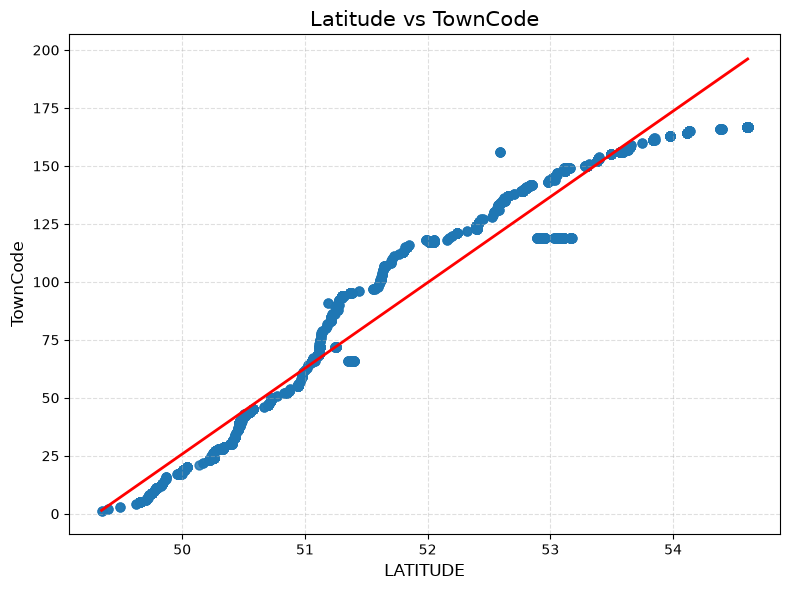

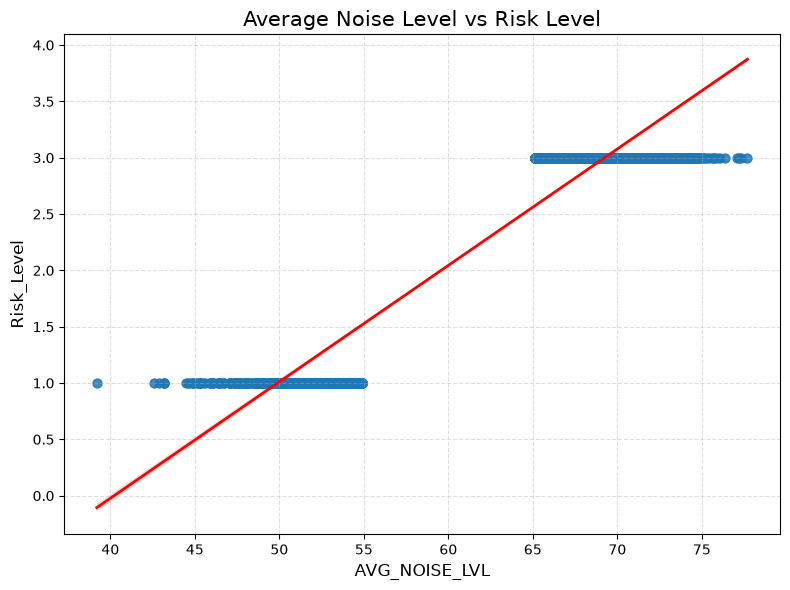

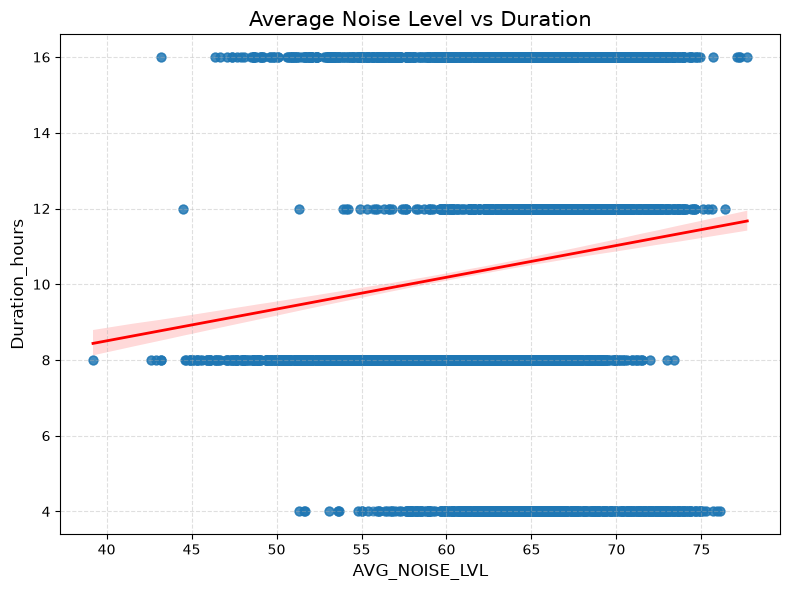

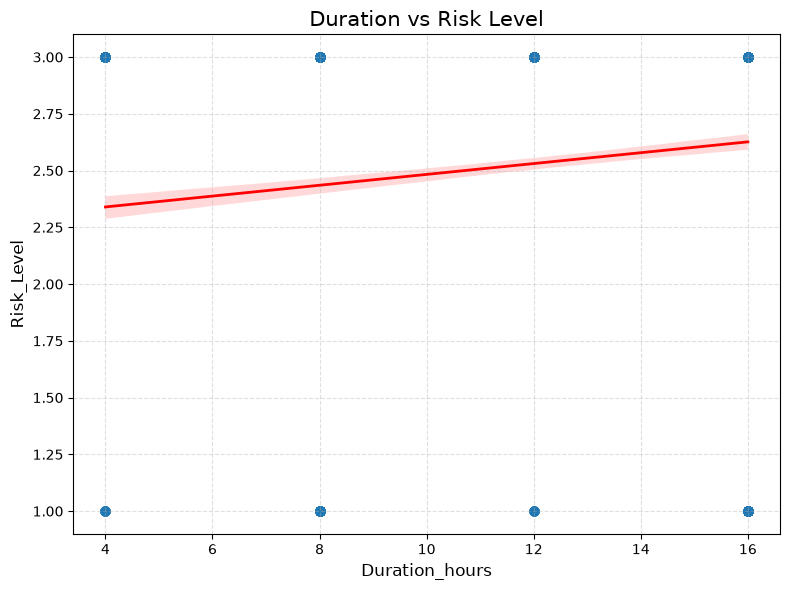

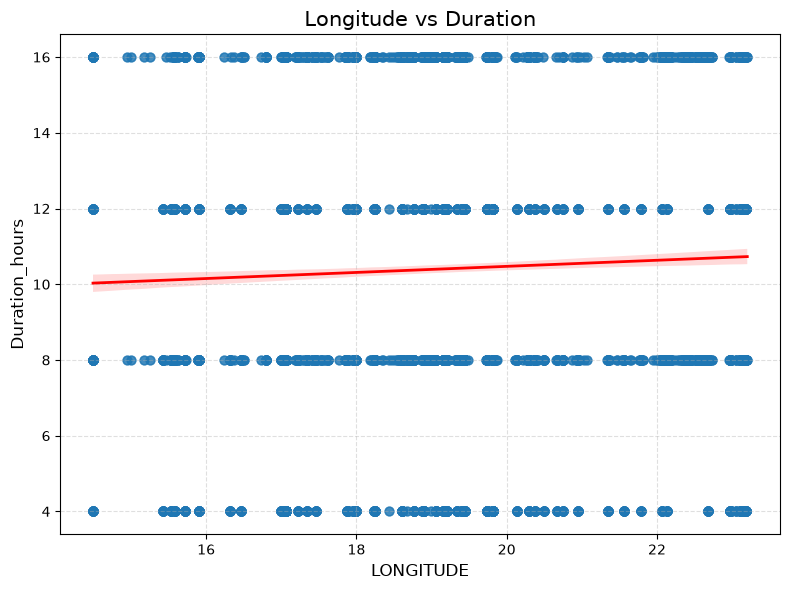


All scatter plots generated successfully.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================
# Load Dataset
# ==========================
file_path = r"Road_noise_measurements_filled (1).xlsx"

df = pd.read_excel(file_path, sheet_name="Road_noise_measurements")

# ==========================================================
# Create TownCode (Latitude -> Longitude order)
# ==========================================================

town_locations = (
    df.groupby("TOWN")[["LATITUDE", "LONGITUDE"]]
      .first()
      .reset_index()
)

town_locations = town_locations.sort_values(
    by=["LATITUDE", "LONGITUDE"],
    ascending=[True, True]
).reset_index(drop=True)

town_locations["TownCode"] = range(1, len(town_locations)+1)

df = df.merge(
    town_locations[["TOWN","TownCode"]],
    on="TOWN",
    how="left"
)

# ==========================================================
# Convert Risk Level
# ==========================================================

risk_mapping = {
    "Low":1,
    "Medium":2,
    "High":3
}

df["Risk_Level"] = df["Risk_Level"].map(risk_mapping)

# ==========================================================
# Scatter Plot Function
# ==========================================================

def scatter_plot(x, y, title, filename):

    plt.figure(figsize=(8,6))

    sns.regplot(
        data=df,
        x=x,
        y=y,
        scatter_kws={
            "alpha":0.6,
            "s":40
        },
        line_kws={
            "color":"red",
            "linewidth":2
        }
    )

    plt.title(title, fontsize=15)
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)

    plt.grid(True, linestyle="--", alpha=0.4)

    plt.tight_layout()

    plt.savefig(filename, dpi=300)

    plt.show()

# ==========================================================
# Generate Scatter Plots
# ==========================================================

scatter_plot(
    "LATITUDE",
    "TownCode",
    "Latitude vs TownCode",
    "Latitude_vs_TownCode.png"
)

scatter_plot(
    "AVG_NOISE_LVL",
    "Risk_Level",
    "Average Noise Level vs Risk Level",
    "Noise_vs_Risk.png"
)

scatter_plot(
    "AVG_NOISE_LVL",
    "Duration_hours",
    "Average Noise Level vs Duration",
    "Noise_vs_Duration.png"
)

scatter_plot(
    "Duration_hours",
    "Risk_Level",
    "Duration vs Risk Level",
    "Duration_vs_Risk.png"
)

scatter_plot(
    "LONGITUDE",
    "Duration_hours",
    "Longitude vs Duration",
    "Longitude_vs_Duration.png"
)

print("\nAll scatter plots generated successfully.")